In [ ]:
!pip install gensim
import gensim

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import os
import pickle
from bs4 import BeautifulSoup

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Embedding, LSTM, Bidirectional, GlobalAveragePooling1D, Dropout, SimpleRNN, GRU
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.initializers import Constant
from gensim.models import Word2Vec

from google.colab import drive
drive.mount('/content/drive')


BASE_PATH = '/content/drive/MyDrive/440_Project'
RESULTS_FILE = os.path.join(BASE_PATH, 'FINAL_SEPARATED_RESULTS.csv')
MODELS_DIR = os.path.join(BASE_PATH, 'saved_models_final')
FEATURES_DIR = os.path.join(BASE_PATH, 'saved_features')


for d in [MODELS_DIR, FEATURES_DIR]:
    if not os.path.exists(d):
        os.makedirs(d)


nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt_tab')
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

print("Setup Complete.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 110.3 MB/s eta 0:00:00
Mounted at /content/drive


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...


Setup Complete.


[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


EDA of the dataset

Loading Training Data from: /content/drive/MyDrive/440_Project/Question Answer Classification Dataset 4.csv

1. DATASET OVERVIEW
Total Rows: 93333
Total Columns: 2

Missing Values:
 QA Text    0
Class      0
dtype: int64

Duplicate Rows: 0

2. CLASS DISTRIBUTION
Class
Family & Relationships    9432
Politics & Government     9432
Computers & Internet      9429
Sports                    9404
Education & Reference     9385
Business & Finance        9350
Society & Culture         9271
Health                    9263
Science & Mathematics     9217
Entertainment & Music     9150
Name: count, dtype: int64


/tmp/ipython-input-2565627025.py:42: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=df['Class'], order=class_counts.index, palette='viridis')


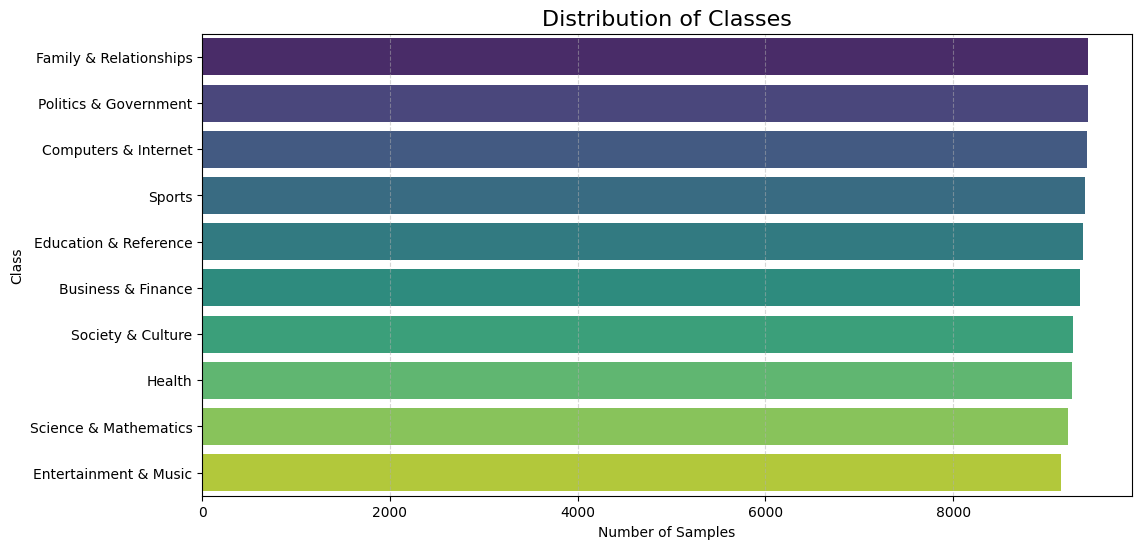


3. TEXT STATISTICS
         char_count    word_count  avg_word_len
count  93333.000000  93333.000000  93333.000000
mean     635.105933    106.572156      6.064437
std      580.559597     99.139635      0.999767
min      128.000000     16.000000      2.648464
25%      289.000000     46.000000      5.604396
50%      452.000000     75.000000      5.932203
75%      753.000000    129.000000      6.327044
max     5973.000000    997.000000     99.571429


/tmp/ipython-input-2565627025.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='word_count', y='Class', data=df, palette='Set2')


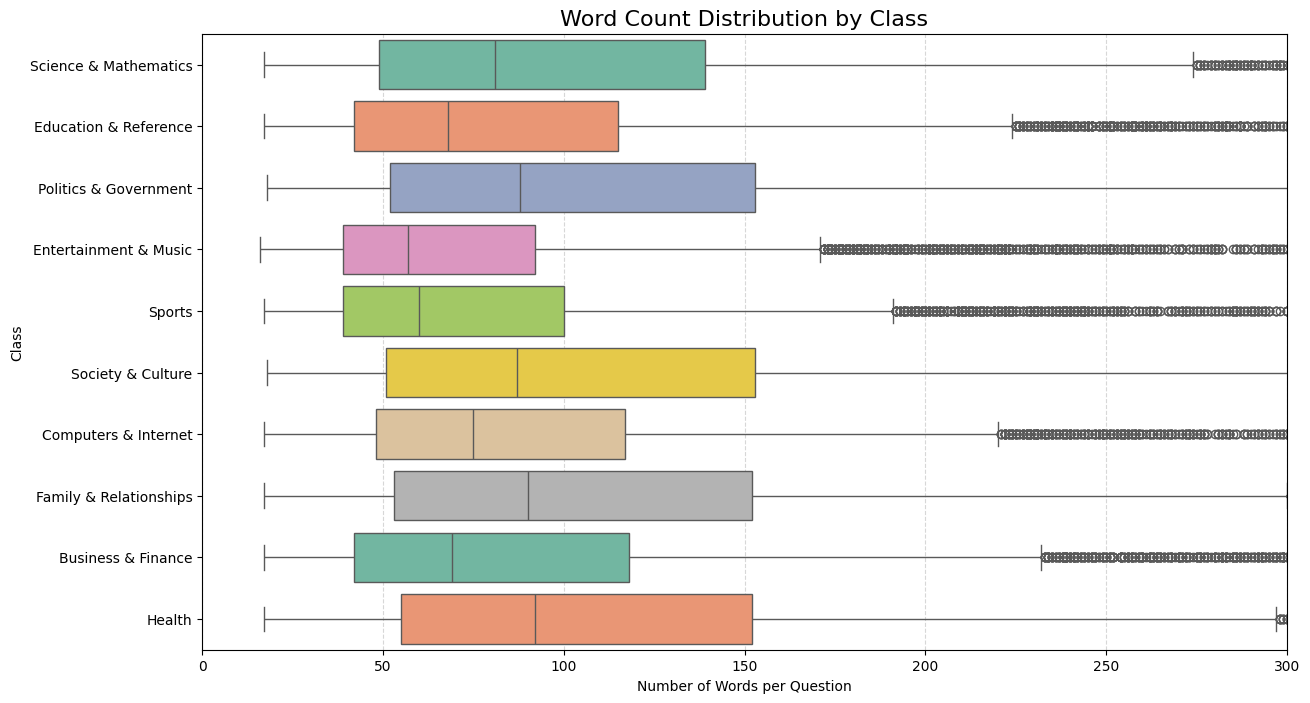


4. NOISE ANALYSIS (HTML)
Rows containing HTML artifacts: 93333 (100.00%)

Processing text for N-Grams (this takes a moment)...

5. TOP UNIGRAMS & BIGRAMS


/tmp/ipython-input-2565627025.py:100: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Count', y='Term', data=top_df, palette='rocket')


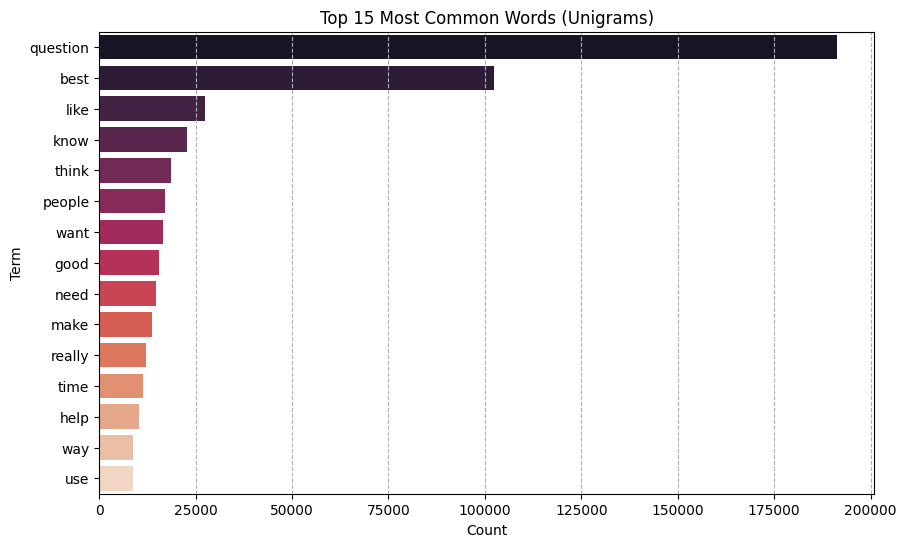

/tmp/ipython-input-2565627025.py:100: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Count', y='Term', data=top_df, palette='rocket')


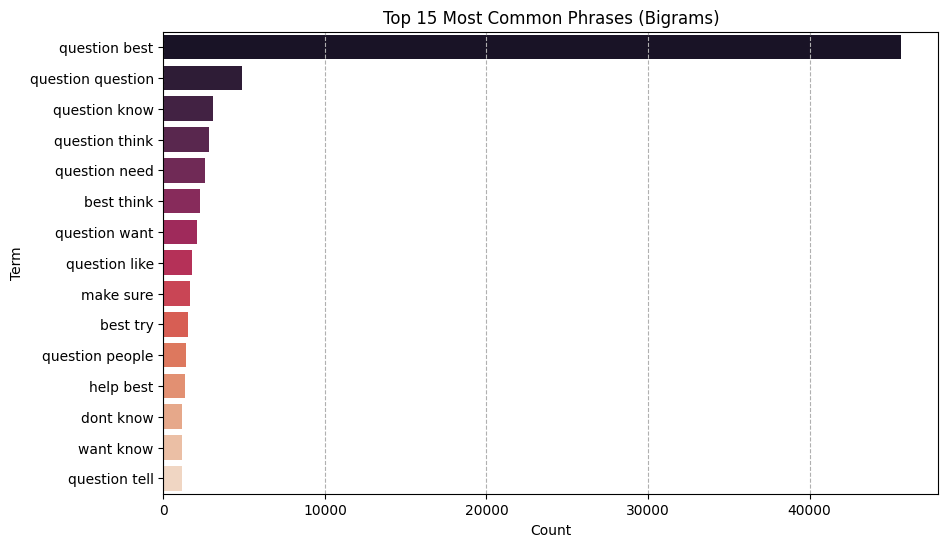


6. WORD CLOUDS PER CLASS


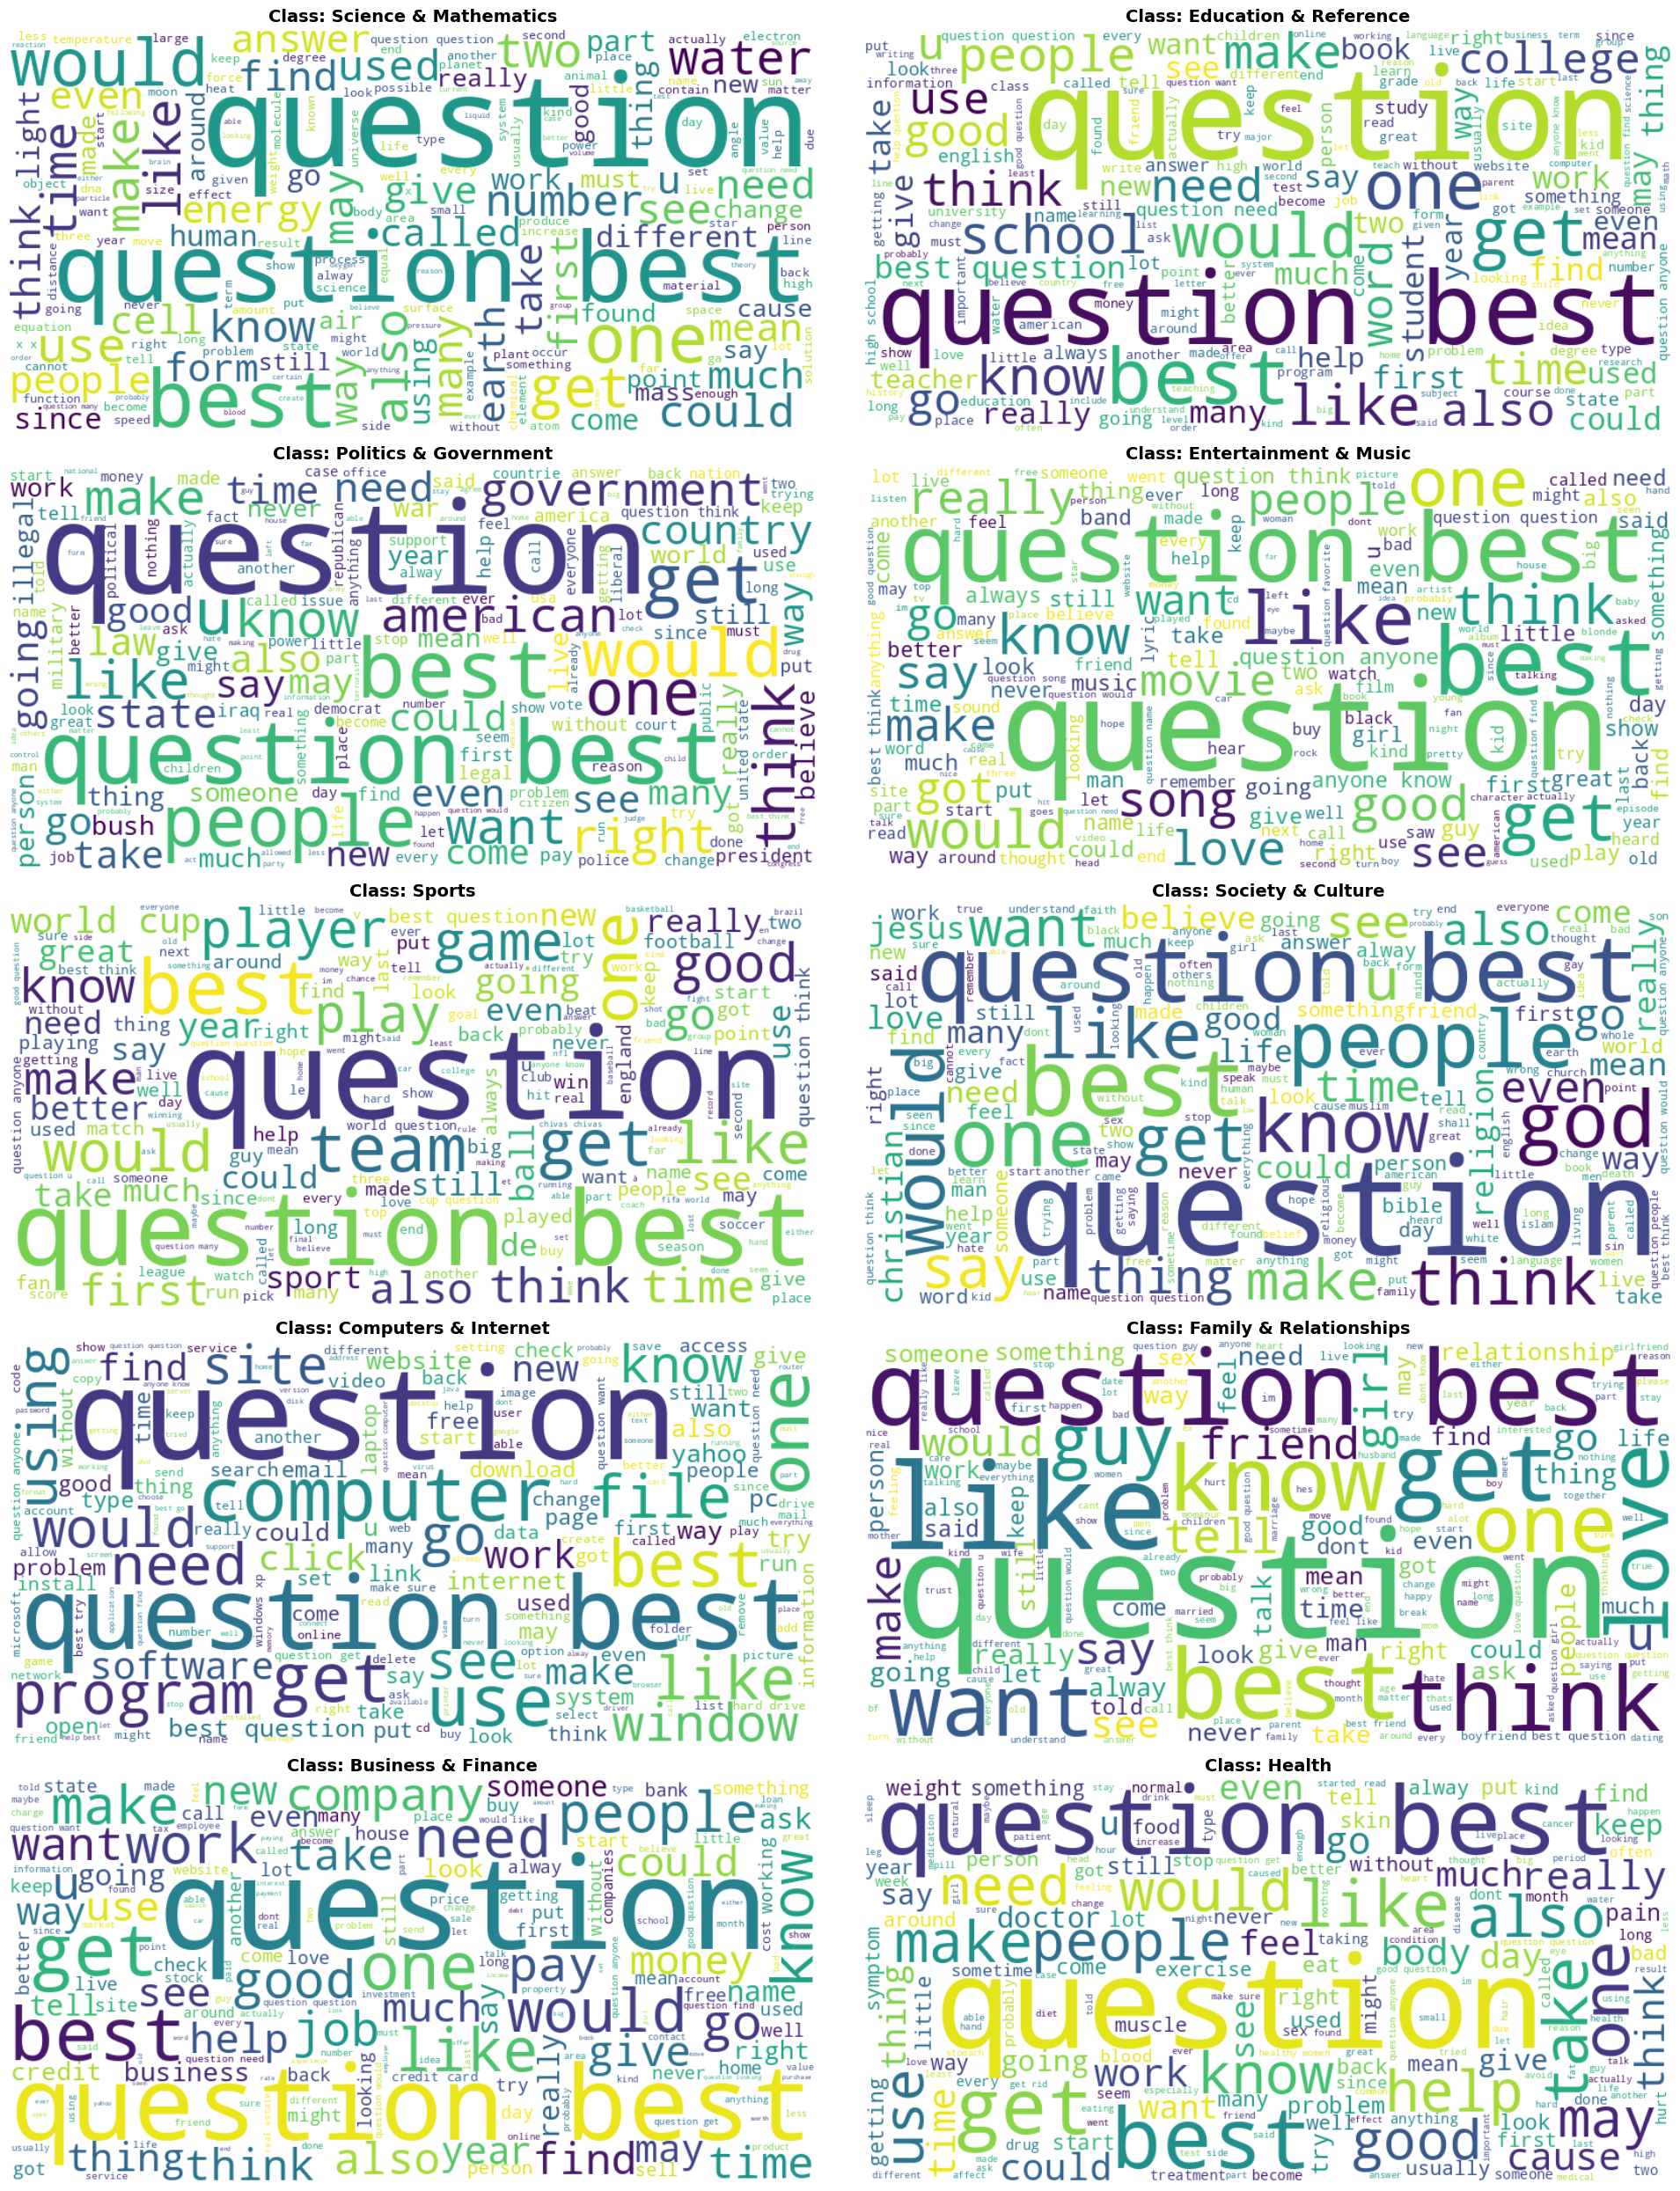


7. WORD CO-OCCURRENCE MATRIX


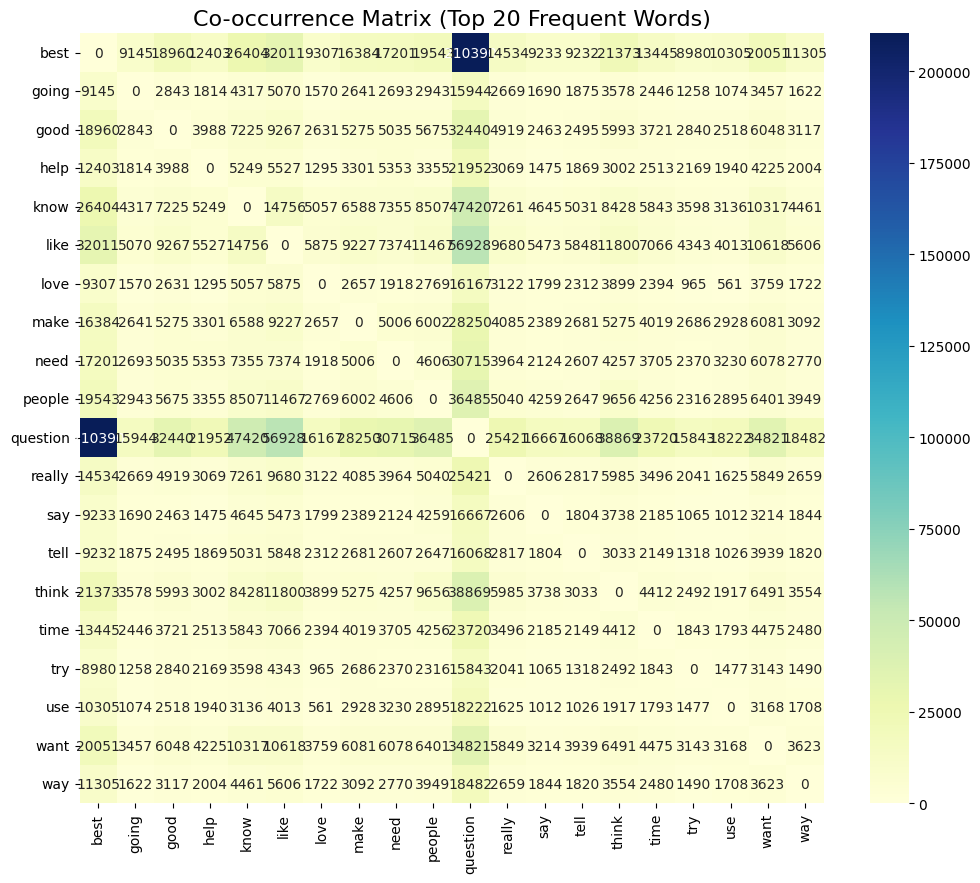

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer
import nltk
from nltk.corpus import stopwords
from bs4 import BeautifulSoup
import os

# Ensure NLTK resources are available
nltk.download('stopwords', quiet=True)
stop_words = set(stopwords.words('english'))

# --- 1. SETUP & LOAD DATA ---
# Update path if necessary
BASE_PATH = '/content/drive/MyDrive/440_Project'
train_path = os.path.join(BASE_PATH, 'Question Answer Classification Dataset 4.csv')

print(f"Loading Training Data from: {train_path}")
df = pd.read_csv(train_path)

# --- 2. BASIC HEALTH CHECK ---
print("\n" + "="*40)
print("1. DATASET OVERVIEW")
print("="*40)
print(f"Total Rows: {df.shape[0]}")
print(f"Total Columns: {df.shape[1]}")
print("\nMissing Values:\n", df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())

# --- 3. CLASS DISTRIBUTION (Target Analysis) ---
print("\n" + "="*40)
print("2. CLASS DISTRIBUTION")
print("="*40)
class_counts = df['Class'].value_counts()
print(class_counts)

plt.figure(figsize=(12, 6))
sns.countplot(y=df['Class'], order=class_counts.index, palette='viridis')
plt.title('Distribution of Classes', fontsize=16)
plt.xlabel('Number of Samples')
plt.ylabel('Class')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.show()

# --- 4. TEXT LENGTH ANALYSIS (Feature Engineering) ---
# We calculate stats on the RAW text first
df['char_count'] = df['QA Text'].astype(str).apply(len)
df['word_count'] = df['QA Text'].astype(str).apply(lambda x: len(x.split()))
df['avg_word_len'] = df['char_count'] / (df['word_count'] + 1) # +1 to avoid div by zero

print("\n" + "="*40)
print("3. TEXT STATISTICS")
print("="*40)
print(df[['char_count', 'word_count', 'avg_word_len']].describe())

# Plot Word Counts by Class (Boxplot)
plt.figure(figsize=(14, 8))
sns.boxplot(x='word_count', y='Class', data=df, palette='Set2')
plt.title('Word Count Distribution by Class', fontsize=16)
plt.xlabel('Number of Words per Question')
plt.xlim(0, 300) # Limit x-axis to zoom in (ignore extreme outliers for view)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.show()

# --- 5. NOISE ANALYSIS (HTML Tags) ---
# Check how many rows contain common HTML tags
html_tags = ['<br>', '<div>', 'href', 'span', '&nbsp;']
rows_with_html = df['QA Text'].astype(str).apply(lambda x: any(tag in x for tag in html_tags)).sum()
print("\n" + "="*40)
print("4. NOISE ANALYSIS (HTML)")
print("="*40)
print(f"Rows containing HTML artifacts: {rows_with_html} ({rows_with_html/len(df)*100:.2f}%)")

# --- 6. N-GRAM ANALYSIS (Top Words & Phrases) ---
# We need a quick clean function just for EDA (Basic)
def basic_clean(text):
    soup = BeautifulSoup(str(text), "html.parser")
    text = soup.get_text(separator=" ").lower()
    # Keep only alphabet characters
    words = [w for w in text.split() if w.isalpha() and w not in stop_words]
    return " ".join(words)

print("\nProcessing text for N-Grams (this takes a moment)...")
df['Cleaned_EDA'] = df['QA Text'].apply(basic_clean)

def plot_top_ngrams(text_series, n=1, title="Top Words"):
    vec = CountVectorizer(ngram_range=(n, n), stop_words='english').fit(text_series)
    bag_of_words = vec.transform(text_series)
    sum_words = bag_of_words.sum(axis=0)
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)

    # Plot
    top_df = pd.DataFrame(words_freq[:15], columns=['Term', 'Count'])
    plt.figure(figsize=(10, 6))
    sns.barplot(x='Count', y='Term', data=top_df, palette='rocket')
    plt.title(title)
    plt.grid(axis='x', linestyle='--')
    plt.show()

print("\n" + "="*40)
print("5. TOP UNIGRAMS & BIGRAMS")
print("="*40)
plot_top_ngrams(df['Cleaned_EDA'], n=1, title="Top 15 Most Common Words (Unigrams)")
plot_top_ngrams(df['Cleaned_EDA'], n=2, title="Top 15 Most Common Phrases (Bigrams)")

# --- 7. WORD CLOUDS BY CLASS ---
print("\n" + "="*40)
print("6. WORD CLOUDS PER CLASS")
print("="*40)

unique_classes = df['Class'].unique()
# Plot grid of word clouds
cols = 2
rows = int(np.ceil(len(unique_classes) / cols))

plt.figure(figsize=(20, 5 * rows))

for i, label in enumerate(unique_classes):
    subset = df[df['Class'] == label]['Cleaned_EDA']
    text_blob = " ".join(subset.values)

    wc = WordCloud(width=800, height=400, background_color='white', stopwords=stop_words).generate(text_blob)

    plt.subplot(rows, cols, i+1)
    plt.imshow(wc, interpolation='bilinear')
    plt.title(f"Class: {label}", fontsize=14, fontweight='bold')
    plt.axis('off')

plt.tight_layout()
plt.show()

# --- 8. CO-OCCURRENCE MATRIX ---
print("\n" + "="*40)
print("7. WORD CO-OCCURRENCE MATRIX")
print("="*40)

# Limit to top 20 words for clarity in the matrix
cv_cooc = CountVectorizer(stop_words='english', max_features=20)
word_counts = cv_cooc.fit_transform(df['Cleaned_EDA'])

# Calculate co-occurrence by multiplying matrix by its transpose
# co_occurrence = (Document-Term Matrix)^T * (Document-Term Matrix)
co_occurrence_matrix = (word_counts.T * word_counts)

# Set the diagonal to 0 so we don't just see how many times a word appears with itself
co_occurrence_matrix.setdiag(0)

# Get word names for labeling
names = cv_cooc.get_feature_names_out()
df_cooc = pd.DataFrame(data=co_occurrence_matrix.toarray(), columns=names, index=names)

# Plotting the Heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(df_cooc, annot=True, fmt='d', cmap='YlGnBu', cbar=True)
plt.title('Co-occurrence Matrix (Top 20 Frequent Words)', fontsize=16)
plt.show()

Preprocessing done for models - tokenization, lemmatization, stopword removal (Skip-gram + TD-IDF as well)

In [ ]:

PICKLE_PATH = os.path.join(FEATURES_DIR, 'objects.pkl')
NUMPY_PATH = os.path.join(FEATURES_DIR, 'arrays.npz')

MAX_WORDS = 10000
MAX_LEN = 200

def generate_and_save_features():
    print("No saved features found. Generating from scratch... (This takes time)")


    train_path = os.path.join(BASE_PATH, 'Question Answer Classification Dataset 4.csv')
    test_path = os.path.join(BASE_PATH, '[Updated] Question Answer Classification Dataset[Test].csv') # UPDATE THIS
    df_train = pd.read_csv(train_path)
    df_test = pd.read_csv(test_path)

    # 2. Cleaning
    stop_words = set(stopwords.words('english'))
    lemmatizer = WordNetLemmatizer()

    def clean_text(text):
        text = str(text)
        soup = BeautifulSoup(text, "html.parser")
        clean = soup.get_text(separator=" ")
        tokens = word_tokenize(clean)
        processed = [lemmatizer.lemmatize(t.lower()) for t in tokens if t.lower() not in stop_words and t.isalnum()]
        return " ".join(processed)

    print("   Cleaning Text...")
    df_train['Cleaned_Text'] = df_train['QA Text'].apply(clean_text)
    df_test['Cleaned_Text'] = df_test['QA Text'].apply(clean_text)

    # 3. Label Encoding
    le = LabelEncoder()
    y_train_indices = le.fit_transform(df_train['Class'])
    y_test_indices = le.transform(df_test['Class'])
    class_names = le.classes_
    y_train_cat = to_categorical(y_train_indices)
    y_test_cat = to_categorical(y_test_indices)

    # 4. TF-IDF
    print("   Vectorizing TF-IDF...")
    tfidf = TfidfVectorizer(max_features=5000)
    X_train_tfidf = tfidf.fit_transform(df_train['Cleaned_Text']).toarray()
    X_test_tfidf = tfidf.transform(df_test['Cleaned_Text']).toarray()

    # 5. Sequences
    print("   Tokenizing Sequences...")
    tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
    tokenizer.fit_on_texts(df_train['Cleaned_Text'])
    X_train_seq = tokenizer.texts_to_sequences(df_train['Cleaned_Text'])
    X_test_seq = tokenizer.texts_to_sequences(df_test['Cleaned_Text'])
    X_train_pad = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding='post', truncating='post')
    X_test_pad = pad_sequences(X_test_seq, maxlen=MAX_LEN, padding='post', truncating='post')

    # 6. Skip-gram Embeddings
    print("   Training Word2Vec...")
    sentences = [t.split() for t in df_train['Cleaned_Text']]
    w2v_base = Word2Vec(sentences, vector_size=128, window=5, min_count=1, workers=4, sg=1)
    w2v_tuned = Word2Vec(sentences, vector_size=200, window=5, min_count=1, workers=4, sg=1)

    def create_emb_matrix(w2v, dim):
        vocab_len = len(tokenizer.word_index) + 1
        matrix = np.zeros((vocab_len, dim))
        for word, i in tokenizer.word_index.items():
            if word in w2v.wv:
                matrix[i] = w2v.wv[word]
            else:
                matrix[i] = np.random.normal(scale=0.6, size=(dim,))
        return matrix, vocab_len

    emb_base, vocab_size = create_emb_matrix(w2v_base, 128)
    emb_tuned, _ = create_emb_matrix(w2v_tuned, 200)

    # 7. SAVE EVERYTHING
    print("   Saving artifacts to Drive...")

    # Save Objects
    with open(PICKLE_PATH, 'wb') as f:
        pickle.dump({
            'tokenizer': tokenizer,
            'tfidf': tfidf,
            'le': le,
            'class_names': class_names,
            'vocab_size': vocab_size
        }, f)

    # Save Arrays (Compressed)
    np.savez_compressed(NUMPY_PATH,
                        X_train_tfidf=X_train_tfidf, X_test_tfidf=X_test_tfidf,
                        X_train_pad=X_train_pad, X_test_pad=X_test_pad,
                        y_train_indices=y_train_indices, y_test_indices=y_test_indices,
                        y_train_cat=y_train_cat, y_test_cat=y_test_cat,
                        emb_base=emb_base, emb_tuned=emb_tuned)

    print("Done! Features saved.")
    return (X_train_tfidf, X_test_tfidf, X_train_pad, X_test_pad,
            y_train_indices, y_test_indices, y_train_cat, y_test_cat,
            emb_base, emb_tuned, class_names, vocab_size)

def load_features():
    print("Found saved features in Drive. Loading...")

    # Load Objects
    with open(PICKLE_PATH, 'rb') as f:
        objs = pickle.load(f)

    # Load Arrays
    arrays = np.load(NUMPY_PATH)

    print("Features Loaded successfully!")
    return (arrays['X_train_tfidf'], arrays['X_test_tfidf'],
            arrays['X_train_pad'], arrays['X_test_pad'],
            arrays['y_train_indices'], arrays['y_test_indices'],
            arrays['y_train_cat'], arrays['y_test_cat'],
            arrays['emb_base'], arrays['emb_tuned'],
            objs['class_names'], objs['vocab_size'])

# --- MAIN LOGIC ---
if os.path.exists(PICKLE_PATH) and os.path.exists(NUMPY_PATH):
    # LOAD
    (X_train_tfidf, X_test_tfidf, X_train_pad, X_test_pad,
     y_train_indices, y_test_indices, y_train_cat, y_test_cat,
     emb_base, emb_tuned, class_names, vocab_size) = load_features()
else:
    # GENERATE
    (X_train_tfidf, X_test_tfidf, X_train_pad, X_test_pad,
     y_train_indices, y_test_indices, y_train_cat, y_test_cat,
     emb_base, emb_tuned, class_names, vocab_size) = generate_and_save_features()

# Re-create Splits for training (Fast, so we do it in memory)
print("Creating Validation Splits...")
X_train_tf_split, X_val_tf_split, y_train_tf_split, y_val_tf_split = train_test_split(
    X_train_tfidf, y_train_cat, test_size=0.2, random_state=42
)
X_train_seq_split, X_val_seq_split, y_train_seq_split, y_val_seq_split = train_test_split(
    X_train_pad, y_train_cat, test_size=0.2, random_state=42
)
num_classes = len(class_names)
print("Ready for Modeling!")

Found saved features in Drive. Loading...
Features Loaded successfully!
Creating Validation Splits...
Ready for Modeling!


Saving Models

In [ ]:
results_storage = []

def save_result(result_dict):
    df_new = pd.DataFrame([result_dict])
    if os.path.exists(RESULTS_FILE):
        df_new.to_csv(RESULTS_FILE, mode='a', header=False, index=False)
    else:
        df_new.to_csv(RESULTS_FILE, mode='w', header=True, index=False)
    print(f"   Saved stats to {RESULTS_FILE}")

def evaluate_model(model, X_test, y_test, name, is_neural=True):
    print(f"Evaluating {name}...")
    if is_neural:
        y_pred_probs = model.predict(X_test, verbose=0)
        y_pred = np.argmax(y_pred_probs, axis=1)
        y_true = np.argmax(y_test, axis=1)
        model.save(os.path.join(MODELS_DIR, f"{name.replace(' ', '_')}.keras"))
    else:
        y_pred = model.predict(X_test)
        y_true = y_test
        with open(os.path.join(MODELS_DIR, f"{name.replace(' ', '_')}.pkl"), 'wb') as f:
            pickle.dump(model, f)

    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average='macro')
    report = classification_report(y_true, y_pred, target_names=class_names)
    cm = confusion_matrix(y_true, y_pred)

    print(f"   Accuracy: {acc:.4f} | F1: {f1:.4f}")
    save_result({'name': name, 'accuracy': acc, 'f1_macro': f1})

    return {'name': name, 'accuracy': acc, 'f1': f1, 'report': report, 'cm': cm}

Naive Bayes

In [ ]:
print("--- Naive Bayes (Base) ---")
nb_base = MultinomialNB()
nb_base.fit(X_train_tfidf, y_train_indices)
results_storage.append(evaluate_model(nb_base, X_test_tfidf, y_test_indices, "Naive Bayes (Base)", False))

print("--- Naive Bayes (Tuned) ---")
grid = GridSearchCV(MultinomialNB(), {'alpha': [0.1, 1.0, 5.0, 10.0]}, cv=5, scoring='f1_macro')
grid.fit(X_train_tfidf, y_train_indices)
results_storage.append(evaluate_model(grid.best_estimator_, X_test_tfidf, y_test_indices, "Naive Bayes (Tuned)", False))

--- Naive Bayes (Base) ---
📊 Evaluating Naive Bayes (Base)...
   Accuracy: 0.6669 | F1: 0.6625
   Saved stats to /content/drive/MyDrive/440_Project/FINAL_SEPARATED_RESULTS.csv
--- Naive Bayes (Tuned) ---
📊 Evaluating Naive Bayes (Tuned)...
   Accuracy: 0.6686 | F1: 0.6650
   Saved stats to /content/drive/MyDrive/440_Project/FINAL_SEPARATED_RESULTS.csv


Deep Neural Network (TF-IDF)

In [ ]:
input_dim = X_train_tfidf.shape[1]

print("--- DNN TF-IDF (Base) ---")
model = Sequential([Dense(64, input_dim=input_dim, activation='relu'), Dense(num_classes, activation='softmax')])
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.fit(X_train_tf_split, y_train_tf_split, epochs=10, batch_size=32, validation_data=(X_val_tf_split, y_val_tf_split), verbose=1)
results_storage.append(evaluate_model(model, X_test_tfidf, y_test_cat, "DNN TF-IDF (Base)"))


print("--- DNN TF-IDF (Tuned) ---")
model = Sequential([
    Dense(256, input_dim=input_dim, activation='relu'), Dropout(0.5),
    Dense(128, activation='relu'), Dropout(0.3),
    Dense(num_classes, activation='softmax')
])
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
cbs = [EarlyStopping(patience=5, restore_best_weights=True), ReduceLROnPlateau(patience=3)]
model.fit(X_train_tf_split, y_train_tf_split, epochs=10, batch_size=32, validation_data=(X_val_tf_split, y_val_tf_split), callbacks=cbs, verbose=1)
results_storage.append(evaluate_model(model, X_test_tfidf, y_test_cat, "DNN TF-IDF (Tuned)"))

--- DNN TF-IDF (Base) ---


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 10s 4ms/step - accuracy: 0.5821 - loss: 1.4914 - val_accuracy: 0.6725 - val_loss: 1.0267
Epoch 2/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7171 - loss: 0.8869 - val_accuracy: 0.6691 - val_loss: 1.0358
Epoch 3/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7357 - loss: 0.8149 - val_accuracy: 0.6616 - val_loss: 1.0610
Epoch 4/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7536 - loss: 0.7553 - val_accuracy: 0.6567 - val_loss: 1.0899
Epoch 5/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7698 - loss: 0.7056 - val_accuracy: 0.6529 - val_loss: 1.1282
Epoch 6/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7846 - loss: 0.6566 - val_accuracy: 0.6482 - val_loss: 1.1644
Epoch 7/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8001 - loss: 0.6125 - val_accuracy: 0.6422 - val_loss: 1.2064
Epoch 8/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8190 - loss: 0.5601 -

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 12s 4ms/step - accuracy: 0.5399 - loss: 1.4328 - val_accuracy: 0.6736 - val_loss: 1.0297 - learning_rate: 0.0010
Epoch 2/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7093 - loss: 0.9203 - val_accuracy: 0.6675 - val_loss: 1.0377 - learning_rate: 0.0010
Epoch 3/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7459 - loss: 0.8015 - val_accuracy: 0.6658 - val_loss: 1.0617 - learning_rate: 0.0010
Epoch 4/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7736 - loss: 0.7019 - val_accuracy: 0.6621 - val_loss: 1.1140 - learning_rate: 0.0010
Epoch 5/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8229 - loss: 0.5684 - val_accuracy: 0.6619 - val_loss: 1.1800 - learning_rate: 1.0000e-04
Epoch 6/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8330 - loss: 0.5328 - val_accuracy: 0.6605 - val_loss: 1.2030 - learning_rate: 1.0000e-04
📊 Evaluating DNN TF-IDF (Tuned)...
   Accuracy: 0.6747 | F1: 0.6670

Deep Neural Network (Skip-gram)

In [ ]:
print("--- DNN Skip-gram (Base) ---")
model = Sequential([
    Embedding(vocab_size, 128, embeddings_initializer=Constant(emb_base), input_length=MAX_LEN, trainable=False),
    GlobalAveragePooling1D(),
    Dense(64, activation='relu'), Dense(num_classes, activation='softmax')
])
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.fit(X_train_seq_split, y_train_seq_split, epochs=10, batch_size=32, validation_data=(X_val_seq_split, y_val_seq_split), verbose=0)
results_storage.append(evaluate_model(model, X_test_pad, y_test_cat, "DNN SG (Base)"))

print("--- DNN Skip-gram (Tuned) ---")
model = Sequential([
    Embedding(vocab_size, 200, embeddings_initializer=Constant(emb_tuned), input_length=MAX_LEN, trainable=True),
    GlobalAveragePooling1D(),
    Dense(128, activation='relu'), Dropout(0.5),
    Dense(64, activation='relu'), Dropout(0.3),
    Dense(num_classes, activation='softmax')
])
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
cbs = [EarlyStopping(patience=5, restore_best_weights=True), ReduceLROnPlateau(patience=3)]
model.fit(X_train_seq_split, y_train_seq_split, epochs=10, batch_size=32, validation_data=(X_val_seq_split, y_val_seq_split), callbacks=cbs, verbose=1)
results_storage.append(evaluate_model(model, X_test_pad, y_test_cat, "DNN SG (Tuned)"))

--- DNN Skip-gram (Base) ---


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


📊 Evaluating DNN SG (Base)...
   Accuracy: 0.6695 | F1: 0.6629
   Saved stats to /content/drive/MyDrive/440_Project/FINAL_SEPARATED_RESULTS.csv
--- DNN Skip-gram (Tuned) ---
Epoch 1/10


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


2334/2334 ━━━━━━━━━━━━━━━━━━━━ 31s 5ms/step - accuracy: 0.3248 - loss: 1.9183 - val_accuracy: 0.5816 - val_loss: 1.3038 - learning_rate: 0.0010
Epoch 2/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.5865 - loss: 1.3027 - val_accuracy: 0.5557 - val_loss: 1.3974 - learning_rate: 0.0010
Epoch 3/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.6293 - loss: 1.1864 - val_accuracy: 0.6261 - val_loss: 1.1972 - learning_rate: 0.0010
Epoch 4/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.6409 - loss: 1.1490 - val_accuracy: 0.6546 - val_loss: 1.1066 - learning_rate: 0.0010
Epoch 5/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.6542 - loss: 1.0985 - val_accuracy: 0.6387 - val_loss: 1.1747 - learning_rate: 0.0010
Epoch 6/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.6650 - loss: 1.0632 - val_accuracy: 0.6223 - val_loss: 1.1791 - learning_rate: 0.0010
Epoch 7/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.6723 - loss: 1.042

GRU

In [ ]:
print("--- GRU (Base) ---")
model = Sequential([
    Embedding(vocab_size, 128, embeddings_initializer=Constant(emb_base), input_length=MAX_LEN, trainable=False),
    GRU(64),
    Dense(num_classes, activation='softmax')
])
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.fit(X_train_seq_split, y_train_seq_split, epochs=10, batch_size=32, validation_data=(X_val_seq_split, y_val_seq_split), verbose=1)
results_storage.append(evaluate_model(model, X_test_pad, y_test_cat, "GRU (Base)"))


print("--- GRU (Tuned) ---")
model = Sequential([
    Embedding(vocab_size, 200, embeddings_initializer=Constant(emb_tuned), input_length=MAX_LEN, trainable=True),
    GRU(128, return_sequences=True, dropout=0.2),
    GRU(64, dropout=0.2),
    Dense(64, activation='relu'), Dropout(0.3),
    Dense(num_classes, activation='softmax')
])
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
cbs = [EarlyStopping(patience=5, restore_best_weights=True), ReduceLROnPlateau(patience=3)]
model.fit(X_train_seq_split, y_train_seq_split, epochs=10, batch_size=32, validation_data=(X_val_seq_split, y_val_seq_split), callbacks=cbs, verbose=1)
results_storage.append(evaluate_model(model, X_test_pad, y_test_cat, "GRU (Tuned)"))

--- GRU (Base) ---


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 35s 9ms/step - accuracy: 0.1057 - loss: 2.2934 - val_accuracy: 0.6380 - val_loss: 1.1256
Epoch 2/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 21s 9ms/step - accuracy: 0.6649 - loss: 1.0382 - val_accuracy: 0.6847 - val_loss: 0.9786
Epoch 3/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 21s 9ms/step - accuracy: 0.6931 - loss: 0.9433 - val_accuracy: 0.6953 - val_loss: 0.9440
Epoch 4/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 21s 9ms/step - accuracy: 0.7016 - loss: 0.9160 - val_accuracy: 0.6953 - val_loss: 0.9410
Epoch 5/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 21s 9ms/step - accuracy: 0.7063 - loss: 0.8996 - val_accuracy: 0.6973 - val_loss: 0.9401
Epoch 6/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 21s 9ms/step - accuracy: 0.7087 - loss: 0.8860 - val_accuracy: 0.6942 - val_loss: 0.9433
Epoch 7/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 21s 9ms/step - accuracy: 0.7154 - loss: 0.8654 - val_accuracy: 0.6995 - val_loss: 0.9329
Epoch 8/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 20s 9ms/step - accuracy: 0.7230 - loss: 0

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


2334/2334 ━━━━━━━━━━━━━━━━━━━━ 89s 31ms/step - accuracy: 0.1025 - loss: 2.3017 - val_accuracy: 0.1128 - val_loss: 2.2881 - learning_rate: 0.0010
Epoch 2/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 71s 30ms/step - accuracy: 0.3948 - loss: 1.6861 - val_accuracy: 0.6916 - val_loss: 0.9749 - learning_rate: 0.0010
Epoch 3/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 71s 30ms/step - accuracy: 0.7098 - loss: 0.9394 - val_accuracy: 0.6965 - val_loss: 0.9582 - learning_rate: 0.0010
Epoch 4/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 71s 30ms/step - accuracy: 0.7381 - loss: 0.8399 - val_accuracy: 0.6960 - val_loss: 0.9700 - learning_rate: 0.0010
Epoch 5/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 70s 30ms/step - accuracy: 0.7590 - loss: 0.7714 - val_accuracy: 0.6879 - val_loss: 1.0012 - learning_rate: 0.0010
Epoch 6/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 71s 30ms/step - accuracy: 0.7828 - loss: 0.6964 - val_accuracy: 0.6897 - val_loss: 1.0521 - learning_rate: 0.0010
Epoch 7/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 71s 30ms/step - accuracy: 0.8129 

Bi-GRU

In [ ]:
print("--- Bi-GRU (Base) ---")
model = Sequential([
    Embedding(vocab_size, 128, embeddings_initializer=Constant(emb_base), input_length=MAX_LEN, trainable=False),
    Bidirectional(GRU(64)),
    Dense(num_classes, activation='softmax')
])
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.fit(X_train_seq_split, y_train_seq_split, epochs=10, batch_size=32, validation_data=(X_val_seq_split, y_val_seq_split), verbose=1)
results_storage.append(evaluate_model(model, X_test_pad, y_test_cat, "Bi-GRU (Base)"))


print("--- Bi-GRU (Tuned) ---")
model = Sequential([
    Embedding(vocab_size, 200, embeddings_initializer=Constant(emb_tuned), input_length=MAX_LEN, trainable=True),
    Bidirectional(GRU(128, return_sequences=True, dropout=0.3)),
    Bidirectional(GRU(64, dropout=0.3)),
    Dense(64, activation='relu'), Dropout(0.3),
    Dense(num_classes, activation='softmax')
])
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
cbs = [EarlyStopping(patience=5, restore_best_weights=True), ReduceLROnPlateau(patience=3)]
model.fit(X_train_seq_split, y_train_seq_split, epochs=10, batch_size=32, validation_data=(X_val_seq_split, y_val_seq_split), callbacks=cbs, verbose=1)
results_storage.append(evaluate_model(model, X_test_pad, y_test_cat, "Bi-GRU (Tuned)"))

--- Bi-GRU (Base) ---
Epoch 1/10


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


2334/2334 ━━━━━━━━━━━━━━━━━━━━ 46s 15ms/step - accuracy: 0.5551 - loss: 1.3264 - val_accuracy: 0.6815 - val_loss: 0.9812
Epoch 2/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 34s 15ms/step - accuracy: 0.6873 - loss: 0.9580 - val_accuracy: 0.6920 - val_loss: 0.9500
Epoch 3/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 34s 14ms/step - accuracy: 0.7016 - loss: 0.9195 - val_accuracy: 0.6989 - val_loss: 0.9337
Epoch 4/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 34s 15ms/step - accuracy: 0.7048 - loss: 0.9008 - val_accuracy: 0.6988 - val_loss: 0.9281
Epoch 5/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 34s 15ms/step - accuracy: 0.7119 - loss: 0.8755 - val_accuracy: 0.6981 - val_loss: 0.9332
Epoch 6/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 34s 15ms/step - accuracy: 0.7177 - loss: 0.8583 - val_accuracy: 0.6966 - val_loss: 0.9352
Epoch 7/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 34s 15ms/step - accuracy: 0.7250 - loss: 0.8362 - val_accuracy: 0.7020 - val_loss: 0.9259
Epoch 8/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 34s 15ms/step - accuracy: 0.7299 - loss: 0.81

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


2334/2334 ━━━━━━━━━━━━━━━━━━━━ 124s 45ms/step - accuracy: 0.5311 - loss: 1.4066 - val_accuracy: 0.6996 - val_loss: 0.9508 - learning_rate: 0.0010
Epoch 2/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 105s 45ms/step - accuracy: 0.7081 - loss: 0.9422 - val_accuracy: 0.7061 - val_loss: 0.9377 - learning_rate: 0.0010
Epoch 3/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 105s 45ms/step - accuracy: 0.7349 - loss: 0.8554 - val_accuracy: 0.7018 - val_loss: 0.9594 - learning_rate: 0.0010
Epoch 4/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 105s 45ms/step - accuracy: 0.7595 - loss: 0.7702 - val_accuracy: 0.6945 - val_loss: 0.9976 - learning_rate: 0.0010
Epoch 5/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 105s 45ms/step - accuracy: 0.7745 - loss: 0.7189 - val_accuracy: 0.6933 - val_loss: 1.0489 - learning_rate: 0.0010
Epoch 6/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 105s 45ms/step - accuracy: 0.8055 - loss: 0.6186 - val_accuracy: 0.6948 - val_loss: 1.0681 - learning_rate: 1.0000e-04
Epoch 7/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 105s 45ms/step - accura

LSTM

In [ ]:
print("--- LSTM (Base) ---")
model = Sequential([
    Embedding(vocab_size, 128, embeddings_initializer=Constant(emb_base), input_length=MAX_LEN, trainable=False),
    LSTM(64),
    Dense(num_classes, activation='softmax')
])
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.fit(X_train_seq_split, y_train_seq_split, epochs=10, batch_size=32, validation_data=(X_val_seq_split, y_val_seq_split), verbose=1)
results_storage.append(evaluate_model(model, X_test_pad, y_test_cat, "LSTM (Base)"))

print("--- LSTM (Tuned) ---")
model = Sequential([
    Embedding(vocab_size, 200, embeddings_initializer=Constant(emb_tuned), input_length=MAX_LEN, trainable=True),
    LSTM(128, return_sequences=True, dropout=0.2),
    LSTM(64, dropout=0.2),
    Dense(64, activation='relu'), Dropout(0.3),
    Dense(num_classes, activation='softmax')
])
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
cbs = [EarlyStopping(patience=5, restore_best_weights=True), ReduceLROnPlateau(patience=3)]
model.fit(X_train_seq_split, y_train_seq_split, epochs=10, batch_size=32, validation_data=(X_val_seq_split, y_val_seq_split), callbacks=cbs, verbose=1)
results_storage.append(evaluate_model(model, X_test_pad, y_test_cat, "LSTM (Tuned)"))

--- LSTM (Base) ---
Epoch 1/10


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


2334/2334 ━━━━━━━━━━━━━━━━━━━━ 31s 9ms/step - accuracy: 0.1078 - loss: 2.2962 - val_accuracy: 0.1064 - val_loss: 2.2973
Epoch 2/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 21s 9ms/step - accuracy: 0.1149 - loss: 2.2844 - val_accuracy: 0.5129 - val_loss: 1.4620
Epoch 3/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 21s 9ms/step - accuracy: 0.5907 - loss: 1.2547 - val_accuracy: 0.6539 - val_loss: 1.0871
Epoch 4/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 21s 9ms/step - accuracy: 0.6665 - loss: 1.0436 - val_accuracy: 0.6710 - val_loss: 1.0259
Epoch 5/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 21s 9ms/step - accuracy: 0.6822 - loss: 0.9969 - val_accuracy: 0.6796 - val_loss: 0.9989
Epoch 6/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 21s 9ms/step - accuracy: 0.6895 - loss: 0.9654 - val_accuracy: 0.6838 - val_loss: 0.9860
Epoch 7/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 21s 9ms/step - accuracy: 0.6923 - loss: 0.9570 - val_accuracy: 0.6834 - val_loss: 0.9894
Epoch 8/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 21s 9ms/step - accuracy: 0.6964 - loss: 0.9363 - val

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


2334/2334 ━━━━━━━━━━━━━━━━━━━━ 88s 31ms/step - accuracy: 0.1029 - loss: 2.3025 - val_accuracy: 0.1076 - val_loss: 2.2950 - learning_rate: 0.0010
Epoch 2/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 70s 30ms/step - accuracy: 0.1782 - loss: 2.1496 - val_accuracy: 0.5692 - val_loss: 1.3605 - learning_rate: 0.0010
Epoch 3/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 71s 30ms/step - accuracy: 0.6105 - loss: 1.2824 - val_accuracy: 0.6791 - val_loss: 1.0392 - learning_rate: 0.0010
Epoch 4/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 71s 30ms/step - accuracy: 0.7031 - loss: 1.0061 - val_accuracy: 0.6837 - val_loss: 1.0155 - learning_rate: 0.0010
Epoch 5/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 70s 30ms/step - accuracy: 0.7293 - loss: 0.9078 - val_accuracy: 0.6818 - val_loss: 1.0286 - learning_rate: 0.0010
Epoch 6/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 71s 30ms/step - accuracy: 0.7507 - loss: 0.8289 - val_accuracy: 0.6832 - val_loss: 1.0322 - learning_rate: 0.0010
Epoch 7/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 71s 30ms/step - accuracy: 0.7727 

Bi-LSTM

In [ ]:
print("--- Bi-LSTM (Base) ---")
model = Sequential([
    Embedding(vocab_size, 128, embeddings_initializer=Constant(emb_base), input_length=MAX_LEN, trainable=False),
    Bidirectional(LSTM(64)),
    Dense(num_classes, activation='softmax')
])
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.fit(X_train_seq_split, y_train_seq_split, epochs=10, batch_size=32, validation_data=(X_val_seq_split, y_val_seq_split), verbose=1)
results_storage.append(evaluate_model(model, X_test_pad, y_test_cat, "Bi-LSTM (Base)"))


print("--- Bi-LSTM (Tuned) ---")
model = Sequential([
    Embedding(vocab_size, 200, embeddings_initializer=Constant(emb_tuned), input_length=MAX_LEN, trainable=True),
    Bidirectional(LSTM(128, return_sequences=True, dropout=0.3)),
    Bidirectional(LSTM(64, dropout=0.3)),
    Dense(64, activation='relu'), Dropout(0.3),
    Dense(num_classes, activation='softmax')
])
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
cbs = [EarlyStopping(patience=5, restore_best_weights=True), ReduceLROnPlateau(patience=3)]
model.fit(X_train_seq_split, y_train_seq_split, epochs=10, batch_size=32, validation_data=(X_val_seq_split, y_val_seq_split), callbacks=cbs, verbose=1)
results_storage.append(evaluate_model(model, X_test_pad, y_test_cat, "Bi-LSTM (Tuned)"))

--- Bi-LSTM (Base) ---
Epoch 1/10


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


2334/2334 ━━━━━━━━━━━━━━━━━━━━ 46s 15ms/step - accuracy: 0.5751 - loss: 1.2948 - val_accuracy: 0.6730 - val_loss: 1.0166
Epoch 2/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 35s 15ms/step - accuracy: 0.6833 - loss: 0.9779 - val_accuracy: 0.6874 - val_loss: 0.9767
Epoch 3/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 35s 15ms/step - accuracy: 0.6963 - loss: 0.9333 - val_accuracy: 0.6918 - val_loss: 0.9476
Epoch 4/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 35s 15ms/step - accuracy: 0.7060 - loss: 0.9042 - val_accuracy: 0.6955 - val_loss: 0.9379
Epoch 5/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 35s 15ms/step - accuracy: 0.7118 - loss: 0.8820 - val_accuracy: 0.6989 - val_loss: 0.9278
Epoch 6/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 35s 15ms/step - accuracy: 0.7137 - loss: 0.8639 - val_accuracy: 0.7003 - val_loss: 0.9188
Epoch 7/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 35s 15ms/step - accuracy: 0.7238 - loss: 0.8452 - val_accuracy: 0.7018 - val_loss: 0.9235
Epoch 8/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 35s 15ms/step - accuracy: 0.7285 - loss: 0.82

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


2334/2334 ━━━━━━━━━━━━━━━━━━━━ 124s 46ms/step - accuracy: 0.5369 - loss: 1.4139 - val_accuracy: 0.6898 - val_loss: 0.9900 - learning_rate: 0.0010
Epoch 2/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 106s 45ms/step - accuracy: 0.7069 - loss: 0.9573 - val_accuracy: 0.6992 - val_loss: 0.9568 - learning_rate: 0.0010
Epoch 3/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 106s 45ms/step - accuracy: 0.7330 - loss: 0.8653 - val_accuracy: 0.7003 - val_loss: 0.9735 - learning_rate: 0.0010
Epoch 4/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 106s 45ms/step - accuracy: 0.7546 - loss: 0.7906 - val_accuracy: 0.6959 - val_loss: 0.9851 - learning_rate: 0.0010
Epoch 5/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 106s 45ms/step - accuracy: 0.7772 - loss: 0.7164 - val_accuracy: 0.6928 - val_loss: 1.0225 - learning_rate: 0.0010
Epoch 6/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 106s 45ms/step - accuracy: 0.8078 - loss: 0.6185 - val_accuracy: 0.6943 - val_loss: 1.0624 - learning_rate: 1.0000e-04
Epoch 7/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 106s 45ms/step - accura

RNN Preprocessing

In [ ]:
def clean_text_rnn(text):
    text = str(text).lower()
    soup = BeautifulSoup(text, "html.parser")
    text = soup.get_text(separator=" ")

    # Keep punctuation that matters for questions
    tokens = word_tokenize(text)

    # Keep words only, DO NOT remove stopwords
    tokens = [t for t in tokens if t.isalnum()]

    return " ".join(tokens)

In [ ]:
import os
from google.colab import drive
drive.mount('/content/drive')


BASE_PATH = '/content/drive/MyDrive/440_Project'
RESULTS_FILE = os.path.join(BASE_PATH, 'FINAL_SEPARATED_RESULTS.csv')
MODELS_DIR = os.path.join(BASE_PATH, 'saved_models_final')
FEATURES_DIR = os.path.join(BASE_PATH, 'saved_features')


train_path = os.path.join(BASE_PATH, 'Question Answer Classification Dataset 4.csv')
test_path = os.path.join(BASE_PATH, '[Updated] Question Answer Classification Dataset[Test].csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)
df_train['RNN_Text'] = df_train['QA Text'].apply(clean_text_rnn)
df_test['RNN_Text'] = df_test['QA Text'].apply(clean_text_rnn)
MAX_WORDS = 10000
MAX_LEN = 75   #fix

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(df_train['RNN_Text'])

X_train_seq = tokenizer.texts_to_sequences(df_train['RNN_Text'])
X_test_seq = tokenizer.texts_to_sequences(df_test['RNN_Text'])

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)


sentences = [t.split() for t in df_train['RNN_Text']]

w2v_rnn = Word2Vec(
    sentences=sentences,
    vector_size=128,
    window=5,
    min_count=2,
    workers=4,
    sg=1,          # Skip-gram
    epochs=10
)

embedding_dim = 128
vocab_size = len(tokenizer.word_index) + 1

embedding_matrix = np.zeros((vocab_size, embedding_dim))

for word, i in tokenizer.word_index.items():
    if word in w2v_rnn.wv:
        embedding_matrix[i] = w2v_rnn.wv[word]
    else:
        embedding_matrix[i] = np.random.normal(scale=0.6, size=(embedding_dim,))


le = LabelEncoder()
y_train_indices = le.fit_transform(df_train['Class'])
y_test_indices = le.transform(df_test['Class'])

y_train_cat = to_categorical(y_train_indices)
y_test_cat = to_categorical(y_test_indices)

num_classes = len(le.classes_)



Simple RNN

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
from tensorflow.keras.optimizers import Adam

In [ ]:
simple_rnn = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        weights=[embedding_matrix],
        input_length=MAX_LEN,
        trainable=True
    ),
    SimpleRNN(
        units=64
    ),
    Dense(num_classes, activation='softmax')
])

simple_rnn.compile(
    optimizer=Adam(learning_rate=3e-4, clipnorm=5.0),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

from sklearn.model_selection import train_test_split

X_train_seq_split, X_val_seq_split, y_train_seq_split, y_val_seq_split = train_test_split(
    X_train_pad,
    y_train_cat,
    test_size=0.2,
    random_state=42,
    stratify=y_train_cat.argmax(axis=1)  # important for class balance
)

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_indices),
    y=y_train_indices
)

class_weight = dict(enumerate(class_weights_array))

print("Class weights:", class_weight)

history_simple_rnn = simple_rnn.fit(
    X_train_seq_split,
    y_train_seq_split,
    epochs=10,
    batch_size=32,
    validation_data=(X_val_seq_split, y_val_seq_split),
    class_weight=class_weight,
    verbose=1
)


Class weights: {0: np.float64(0.9982139037433155), 1: np.float64(0.9898504613426662), 2: np.float64(0.9944912093766649), 3: np.float64(1.020032786885246), 4: np.float64(0.9895356234096692), 5: np.float64(1.0075893339091007), 6: np.float64(0.9895356234096692), 7: np.float64(1.0126179884995117), 8: np.float64(1.006719879193183), 9: np.float64(0.9924819225861335)}
Epoch 1/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 30s 11ms/step - accuracy: 0.2187 - loss: 2.1528 - val_accuracy: 0.3934 - val_loss: 1.7751
Epoch 2/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 24s 10ms/step - accuracy: 0.3947 - loss: 1.7849 - val_accuracy: 0.3763 - val_loss: 1.8060
Epoch 3/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 24s 10ms/step - accuracy: 0.4499 - loss: 1.6668 - val_accuracy: 0.5113 - val_loss: 1.5626
Epoch 4/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 25s 11ms/step - accuracy: 0.5207 - loss: 1.5359 - val_accuracy: 0.5580 - val_loss: 1.4933
Epoch 5/10
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 24s 10ms/step - accuracy: 0.5541 - loss: 1.4616 - val_accuracy: 0.

In [ ]:
# Ensure class_names exists for evaluation
class_names = le.classes_.tolist()

print("Class names:", class_names)


Class names: ['Business & Finance', 'Computers & Internet', 'Education & Reference', 'Entertainment & Music', 'Family & Relationships', 'Health', 'Politics & Government', 'Science & Mathematics', 'Society & Culture', 'Sports']


In [ ]:
results_storage.append(evaluate_model(simple_rnn, X_test_pad, y_test_cat, "Simple RNN (Base)"))

📊 Evaluating Simple RNN (Base)...
   Accuracy: 0.5866 | F1: 0.5898
   Saved stats to /content/drive/MyDrive/440_1_Project/FINAL_SEPARATED_RESULTS.csv


In [ ]:
from tensorflow.keras.layers import Dropout
simple_rnn_tuned = Sequential([
    Embedding(
        vocab_size,
        embedding_dim,
        weights=[embedding_matrix],
        input_length=MAX_LEN,
        trainable=True
    ),
    SimpleRNN(
        units=64,
        dropout=0.2,
        recurrent_dropout=0.2
    ),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(num_classes, activation='softmax')
])
simple_rnn_tuned.compile(
    optimizer=Adam(learning_rate=5e-4, clipnorm=5.0),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_simple_rnn_tuned = simple_rnn_tuned.fit(
    X_train_seq_split,
    y_train_seq_split,
    epochs=30,
    batch_size=32,
    validation_data=(X_val_seq_split, y_val_seq_split),
    class_weight=class_weight,
    verbose=1
)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/30
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 33s 12ms/step - accuracy: 0.1167 - loss: 2.3113 - val_accuracy: 0.1947 - val_loss: 2.1484
Epoch 2/30
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 25s 11ms/step - accuracy: 0.1868 - loss: 2.1931 - val_accuracy: 0.2331 - val_loss: 2.0972
Epoch 3/30
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 25s 11ms/step - accuracy: 0.2211 - loss: 2.1363 - val_accuracy: 0.3242 - val_loss: 1.9635
Epoch 4/30
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 25s 11ms/step - accuracy: 0.2460 - loss: 2.0919 - val_accuracy: 0.3562 - val_loss: 1.9082
Epoch 5/30
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 25s 11ms/step - accuracy: 0.2928 - loss: 2.0186 - val_accuracy: 0.3852 - val_loss: 1.8352
Epoch 6/30
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 25s 11ms/step - accuracy: 0.3105 - loss: 1.9846 - val_accuracy: 0.3750 - val_loss: 1.8610
Epoch 7/30
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 25s 11ms/step - accuracy: 0.3174 - loss: 1.9744 - val_accuracy: 0.3675 - val_loss: 1.8639
Epoch 8/30
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 25s 11ms/step - accuracy: 0.2975 -

In [ ]:
results_storage.append(evaluate_model(simple_rnn_tuned, X_test_pad, y_test_cat, "Simple RNN (Tuned)"))

📊 Evaluating Simple RNN (Tuned)...
   Accuracy: 0.4730 | F1: 0.4430
   Saved stats to /content/drive/MyDrive/440_1_Project/FINAL_SEPARATED_RESULTS.csv


Bi-RNN

In [ ]:
from sklearn.model_selection import train_test_split

X_train_seq_split, X_val_seq_split, y_train_seq_split, y_val_seq_split = train_test_split(
    X_train_pad,
    y_train_cat,
    test_size=0.2,
    random_state=42,
    stratify=y_train_cat.argmax(axis=1)  #important for class balance
)

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_indices),
    y=y_train_indices
)

class_weight = dict(enumerate(class_weights_array))

print("Class weights:", class_weight)


Class weights: {0: np.float64(0.9982139037433155), 1: np.float64(0.9898504613426662), 2: np.float64(0.9944912093766649), 3: np.float64(1.020032786885246), 4: np.float64(0.9895356234096692), 5: np.float64(1.0075893339091007), 6: np.float64(0.9895356234096692), 7: np.float64(1.0126179884995117), 8: np.float64(1.006719879193183), 9: np.float64(0.9924819225861335)}


In [ ]:
from tensorflow.keras.layers import Bidirectional
birnn = Sequential([
    Embedding(
        vocab_size,
        embedding_dim,
        weights=[embedding_matrix],
        input_length=MAX_LEN,
        trainable=True
    ),
    Bidirectional(
        SimpleRNN(units=64)
    ),
    Dense(num_classes, activation='softmax')
])

birnn.compile(
    optimizer=Adam(learning_rate=3e-4, clipnorm=5.0),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_birnn = birnn.fit(
    X_train_seq_split,
    y_train_seq_split,
    epochs=15,
    batch_size=32,
    validation_data=(X_val_seq_split, y_val_seq_split),
    class_weight=class_weight,
    verbose=1
)



/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/15
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 45s 17ms/step - accuracy: 0.3568 - loss: 1.8390 - val_accuracy: 0.5885 - val_loss: 1.2761
Epoch 2/15
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 37s 16ms/step - accuracy: 0.6238 - loss: 1.1925 - val_accuracy: 0.6301 - val_loss: 1.1781
Epoch 3/15
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 37s 16ms/step - accuracy: 0.6687 - loss: 1.0687 - val_accuracy: 0.6425 - val_loss: 1.1397
Epoch 4/15
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 37s 16ms/step - accuracy: 0.6960 - loss: 0.9779 - val_accuracy: 0.6495 - val_loss: 1.1235
Epoch 5/15
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 37s 16ms/step - accuracy: 0.7149 - loss: 0.9247 - val_accuracy: 0.6524 - val_loss: 1.1407
Epoch 6/15
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 37s 16ms/step - accuracy: 0.7305 - loss: 0.8690 - val_accuracy: 0.6509 - val_loss: 1.1462
Epoch 7/15
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 37s 16ms/step - accuracy: 0.7454 - loss: 0.8215 - val_accuracy: 0.6593 - val_loss: 1.1282
Epoch 8/15
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 37s 16ms/step - accuracy: 0.7576 -

In [ ]:
results_storage.append(evaluate_model(birnn, X_test_pad, y_test_cat, "BiRNN (Base)"))

📊 Evaluating BiRNN (Base)...
   Accuracy: 0.6358 | F1: 0.6307
   Saved stats to /content/drive/MyDrive/440_Project/FINAL_SEPARATED_RESULTS.csv


In [ ]:
birnn_tuned = Sequential([
    Embedding(
        vocab_size,
        embedding_dim,
        weights=[embedding_matrix],
        input_length=MAX_LEN,
        trainable=True
    ),
    Bidirectional(
        SimpleRNN(
            units=128,
            dropout=0.2,
            recurrent_dropout=0.2
        )
    ),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(num_classes, activation='softmax')
])

birnn_tuned.compile(
    optimizer=Adam(learning_rate=5e-4, clipnorm=5.0),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
history_birnn_tuned = birnn_tuned.fit(
    X_train_seq_split,
    y_train_seq_split,
    epochs=30,
    batch_size=32,
    validation_data=(X_val_seq_split, y_val_seq_split),
    class_weight=class_weight,
    verbose=1
)


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/30
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 51s 19ms/step - accuracy: 0.2237 - loss: 2.1258 - val_accuracy: 0.4779 - val_loss: 1.5204
Epoch 2/30
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 39s 17ms/step - accuracy: 0.4221 - loss: 1.6947 - val_accuracy: 0.5445 - val_loss: 1.3933
Epoch 3/30
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 39s 17ms/step - accuracy: 0.4954 - loss: 1.5198 - val_accuracy: 0.5745 - val_loss: 1.3144
Epoch 4/30
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 39s 17ms/step - accuracy: 0.5422 - loss: 1.4087 - val_accuracy: 0.5967 - val_loss: 1.2617
Epoch 5/30
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 39s 17ms/step - accuracy: 0.5704 - loss: 1.3451 - val_accuracy: 0.6008 - val_loss: 1.2623
Epoch 6/30
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 39s 17ms/step - accuracy: 0.5890 - loss: 1.2842 - val_accuracy: 0.6250 - val_loss: 1.2169
Epoch 7/30
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 39s 17ms/step - accuracy: 0.6045 - loss: 1.2516 - val_accuracy: 0.6224 - val_loss: 1.2101
Epoch 8/30
2334/2334 ━━━━━━━━━━━━━━━━━━━━ 39s 17ms/step - accuracy: 0.6153 -

In [ ]:
results_storage.append(evaluate_model(birnn_tuned, X_test_pad, y_test_cat, "BiRNN (Tuned)"))

📊 Evaluating BiRNN (Tuned)...
   Accuracy: 0.6326 | F1: 0.6286
   Saved stats to /content/drive/MyDrive/440_Project/FINAL_SEPARATED_RESULTS.csv


Comparison of results

Loading Test Data & Features from Drive...
Found 18 models in history.

 Generating Reports & Matrices (Loading models one by one)...
   Processing: Naive Bayes (Base)...
   Processing: Naive Bayes (Tuned)...
   Processing: DNN TF-IDF (Base)...
   Processing: DNN TF-IDF (Tuned)...
   Processing: DNN SG (Base)...
   Processing: DNN SG (Tuned)...
   Processing: GRU (Base)...
   Processing: GRU (Tuned)...
   Processing: Bi-GRU (Base)...
   Processing: Bi-GRU (Tuned)...
   Processing: LSTM (Base)...
   Processing: LSTM (Tuned)...
   Processing: Bi-LSTM (Base)...
   Processing: Bi-LSTM (Tuned)...
   Processing: Simple RNN (Base)...
   Processing: Simple RNN (Tuned)...
   Processing: BiRNN (Base)...
   Processing: BiRNN (Tuned)...

 FINAL MODEL LEADERBOARD
               name  accuracy  f1_macro
     Bi-GRU (Tuned)  0.703762  0.697027
         GRU (Base)  0.700228  0.696212
        GRU (Tuned)  0.700228  0.695583
    Bi-LSTM (Tuned)  0.699945  0.690774
     Bi-LSTM (Base)  0.699095  0.693870

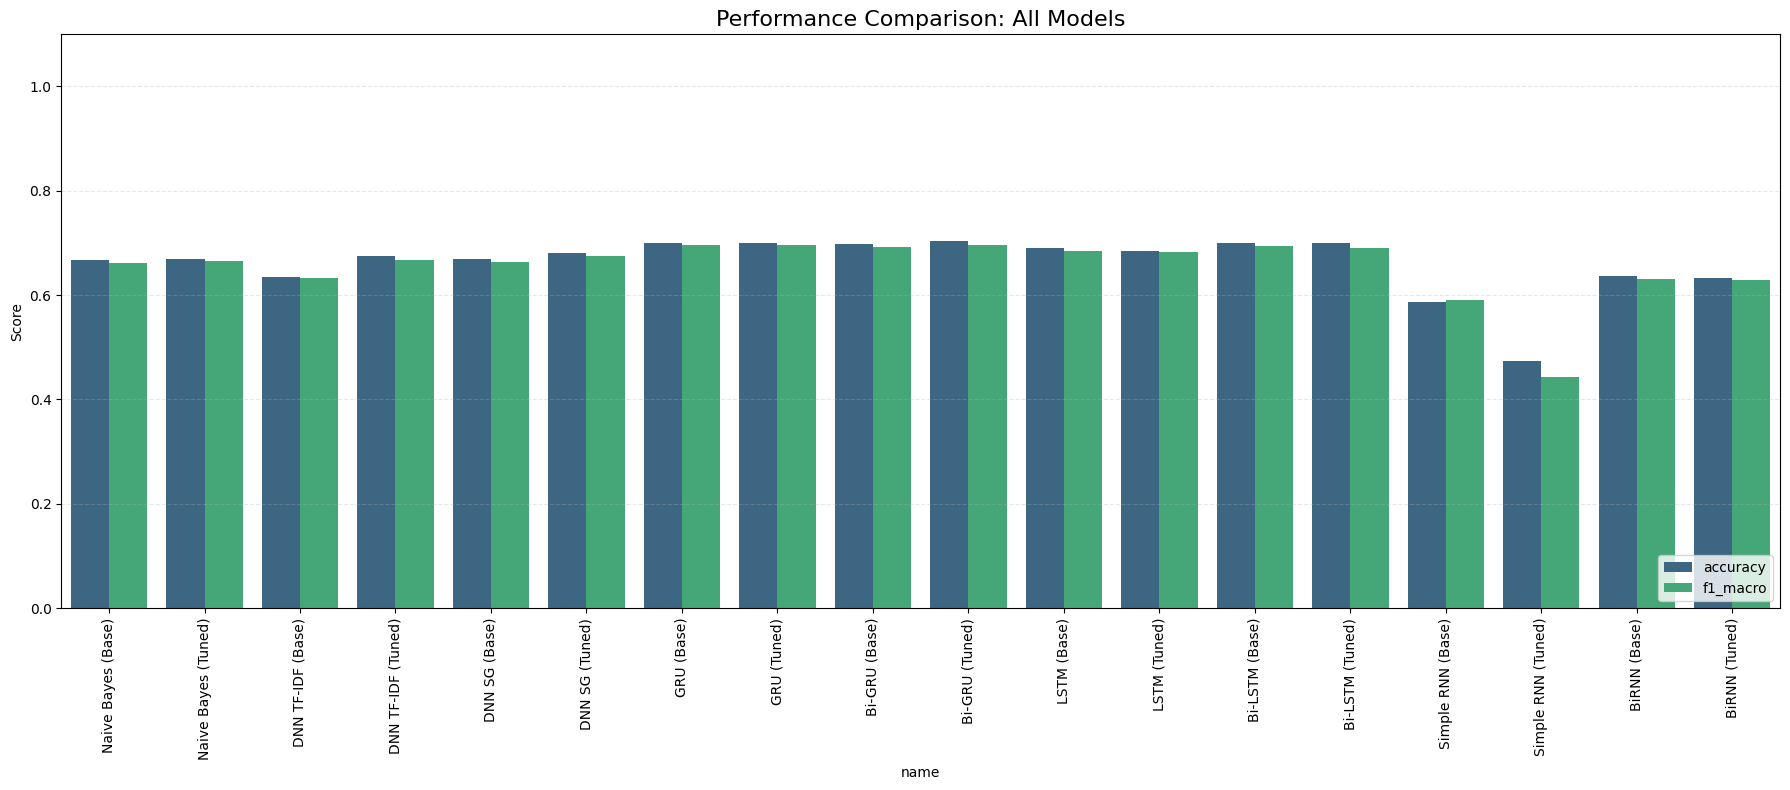


DETAILED CLASSIFICATION REPORTS

--- Model: Naive Bayes (Base) ---
                        precision    recall  f1-score   support

    Business & Finance       0.56      0.49      0.53      6000
  Computers & Internet       0.77      0.86      0.81      6000
 Education & Reference       0.55      0.43      0.48      6000
 Entertainment & Music       0.61      0.63      0.62      6000
Family & Relationships       0.58      0.79      0.67      5999
                Health       0.71      0.76      0.74      6000
 Politics & Government       0.74      0.71      0.73      6000
 Science & Mathematics       0.70      0.70      0.70      6000
     Society & Culture       0.60      0.51      0.55      6000
                Sports       0.82      0.78      0.80      6000

              accuracy                           0.67     59999
             macro avg       0.67      0.67      0.66     59999
          weighted avg       0.67      0.67      0.66     59999


--- Model: Naive Bayes (Tuned) -

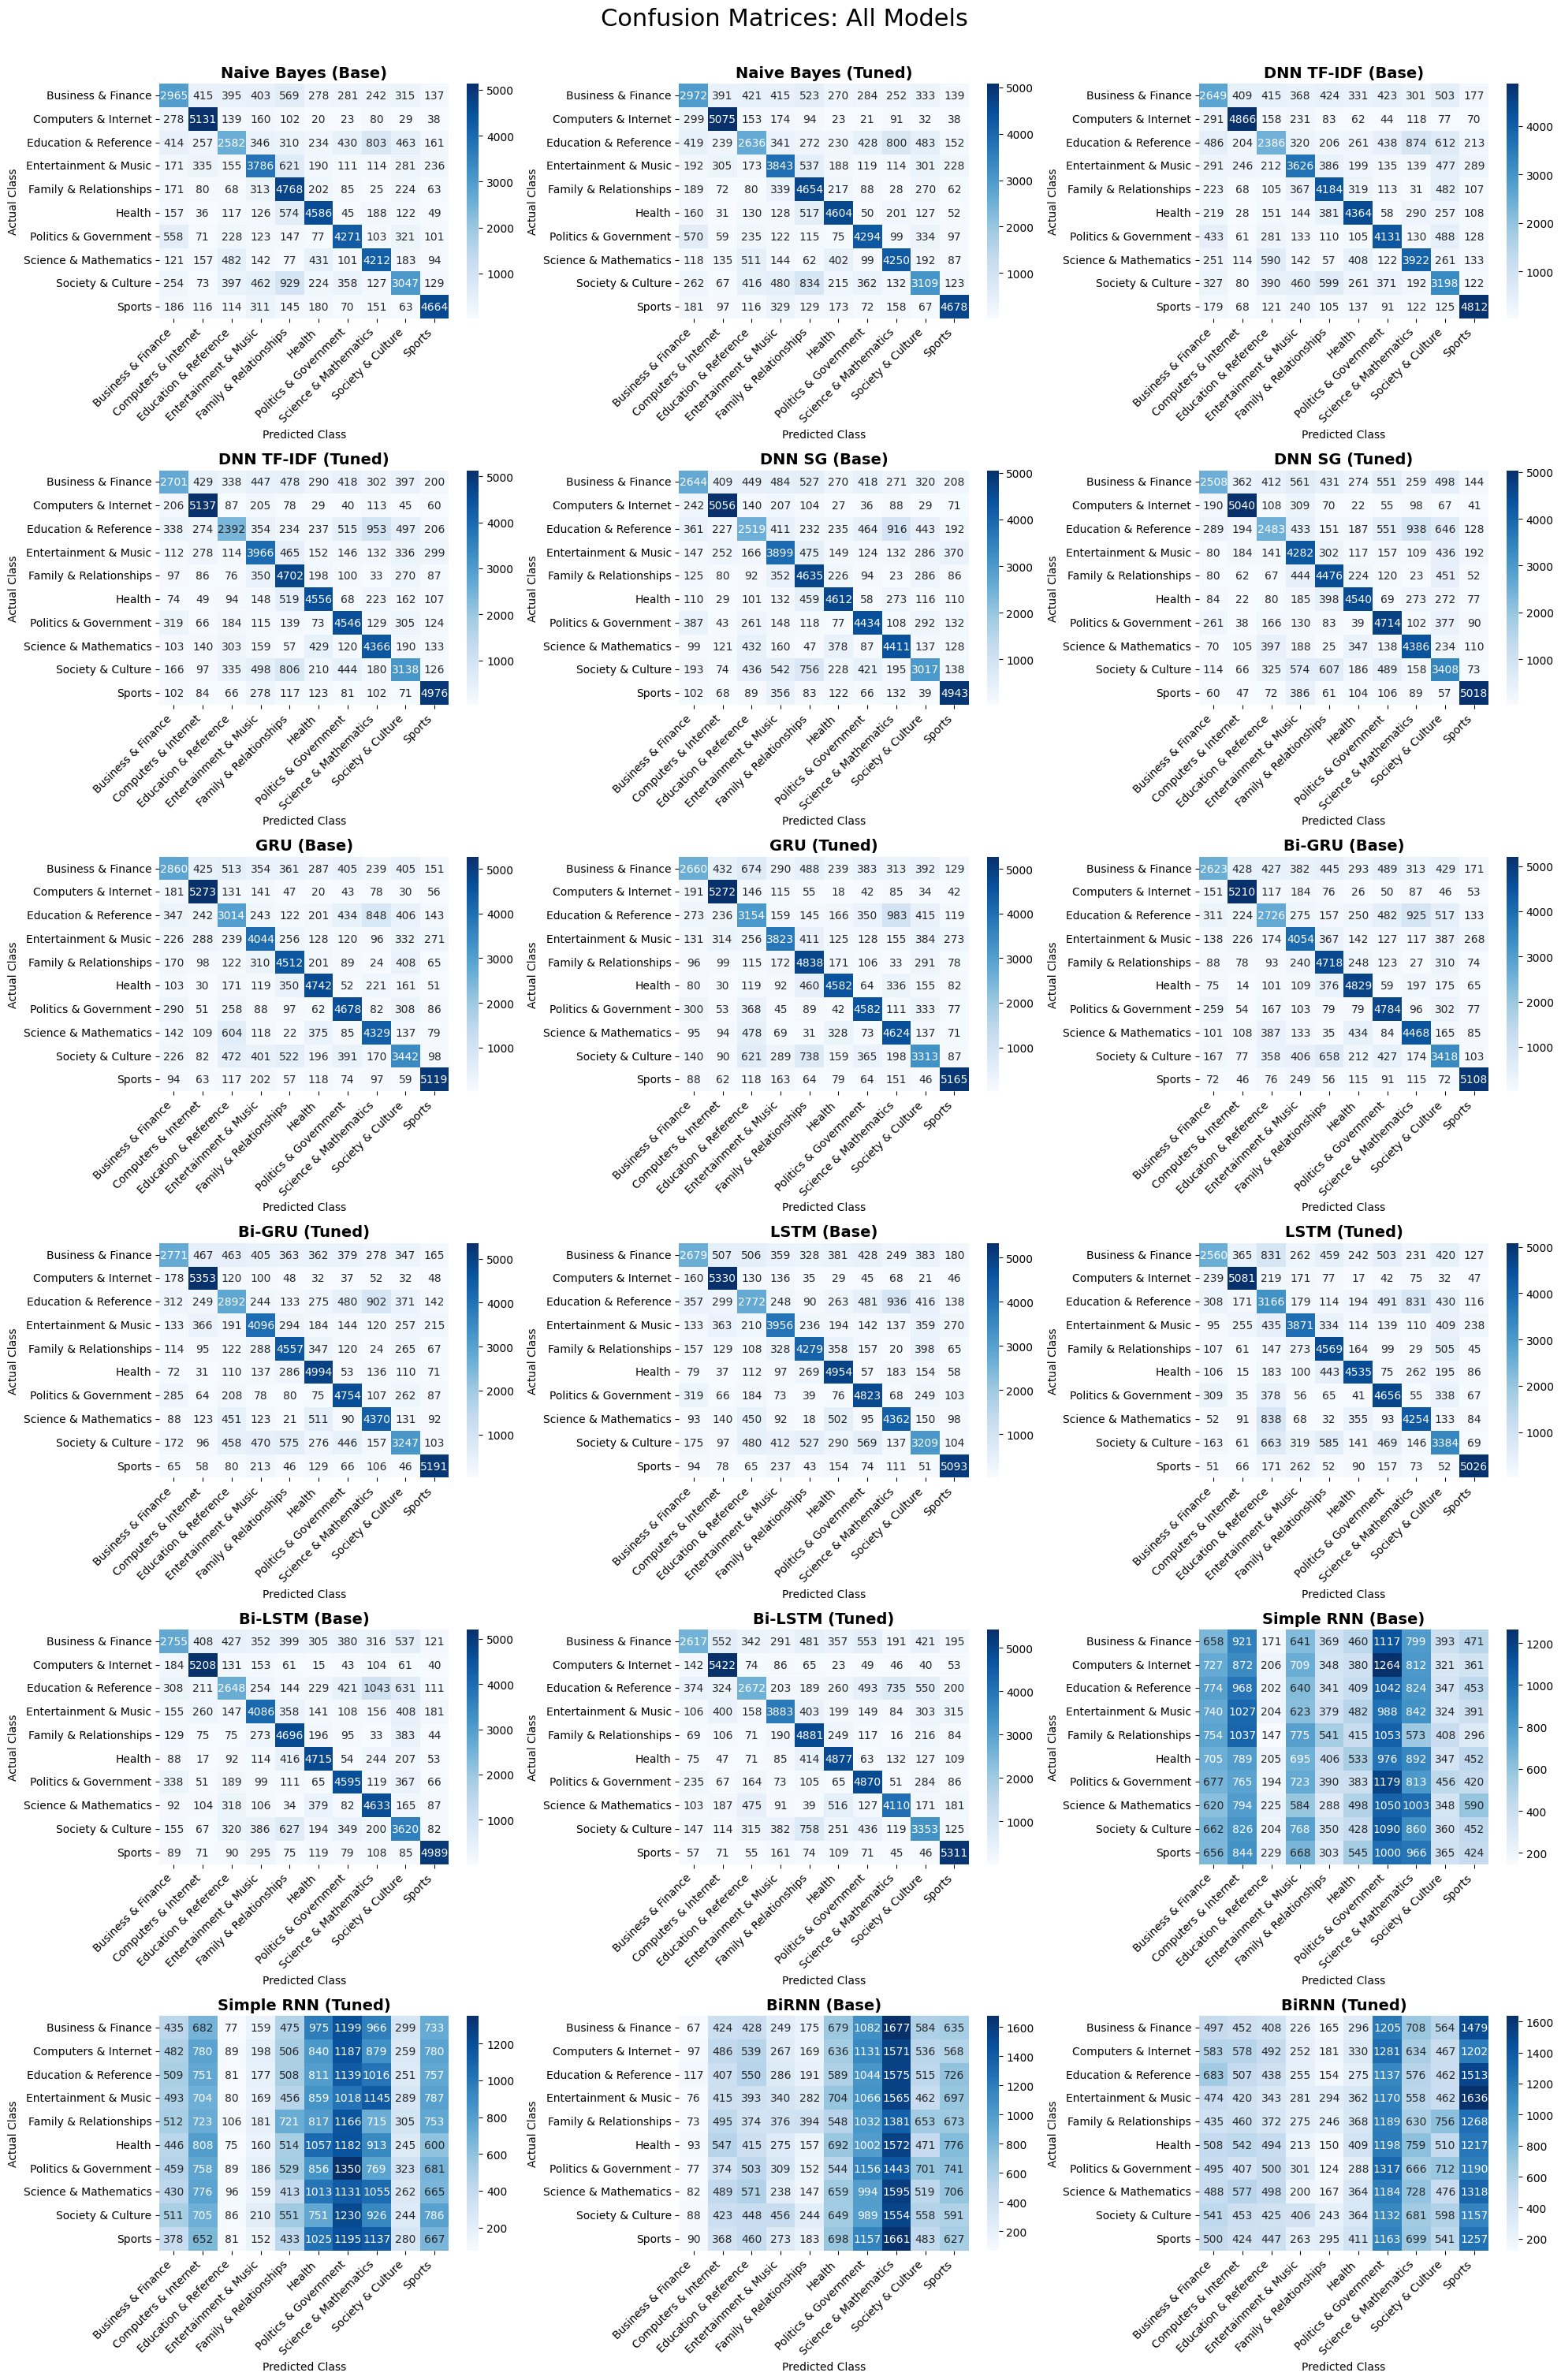

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import pickle
import tensorflow as tf
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from tensorflow.keras.models import load_model

# --- 1. LOAD DATA & RESOURCES FROM DRIVE ---
# We re-load these to ensure this cell works even after a runtime restart
print("Loading Test Data & Features from Drive...")

# Load Objects (Class names, etc.)
with open(os.path.join(FEATURES_DIR, 'objects.pkl'), 'rb') as f:
    objs = pickle.load(f)
class_names = objs['class_names']

# Load Arrays (X_test, y_test)
arrays = np.load(os.path.join(FEATURES_DIR, 'arrays.npz'))
X_test_tfidf = arrays['X_test_tfidf']
X_test_pad = arrays['X_test_pad']
y_test_indices = arrays['y_test_indices'] # For Scikit-learn / Truth
y_test_cat = arrays['y_test_cat']         # For Neural Nets (if needed)

# Load Results Registry
if not os.path.exists(RESULTS_FILE):
    raise FileNotFoundError("No results file found. Run the training cells first!")

final_df = pd.read_csv(RESULTS_FILE)
# Remove duplicates if any (keep last run)
final_df = final_df.drop_duplicates(subset=['name'], keep='last')

print(f"Found {len(final_df)} models in history.")

# --- 2. GENERATE REPORTS & MATRICES ---
confusion_matrices = []
reports = []
names = []

print("\n Generating Reports & Matrices (Loading models one by one)...")

for index, row in final_df.iterrows():
    name = row['name']
    print(f"   Processing: {name}...")

    # A. DETERMINE INPUT TYPE
    # If it's TF-IDF based (Naive Bayes or DNN TF-IDF)
    if "TF-IDF" in name or "Naive Bayes" in name:
        X_input = X_test_tfidf
    else:
        # Sequence based (RNN, LSTM, DNN SG, etc.)
        X_input = X_test_pad

    # B. LOAD MODEL & PREDICT
    filename_base = name.replace(' ', '_')
    keras_path = os.path.join(MODELS_DIR, f"{filename_base}.keras")
    pkl_path = os.path.join(MODELS_DIR, f"{filename_base}.pkl")

    y_pred = None

    try:
        if os.path.exists(keras_path):
            # Load Keras Model
            model = load_model(keras_path)
            preds_prob = model.predict(X_input, verbose=0)
            y_pred = np.argmax(preds_prob, axis=1)
            # Garbage collection to free RAM
            del model
            tf.keras.backend.clear_session()

        elif os.path.exists(pkl_path):
            # Load Sklearn Model
            with open(pkl_path, 'rb') as f:
                model = pickle.load(f)
            y_pred = model.predict(X_input)
            del model

        else:
            print(f" Model file not found for {name}. Skipping...")
            continue

        # C. STORE METRICS
        cm = confusion_matrix(y_test_indices, y_pred)
        rep = classification_report(y_test_indices, y_pred, target_names=class_names)

        confusion_matrices.append(cm)
        reports.append(rep)
        names.append(name)

    except Exception as e:
        print(f" Error processing {name}: {str(e)}")

# --- 3. DISPLAY LEADERBOARD ---
print("\n" + "="*40)
print(" FINAL MODEL LEADERBOARD")
print("="*40)
print(final_df.sort_values(by='accuracy', ascending=False)[['name', 'accuracy', 'f1_macro']].to_string(index=False))

# --- 4. PLOT BAR CHART ---
plt.figure(figsize=(18, 8))
df_melt = final_df.melt(id_vars="name", value_vars=['accuracy', 'f1_macro'], var_name="Metric", value_name="Score")
sns.barplot(data=df_melt, x="name", y="Score", hue="Metric", palette="viridis")
plt.title("Performance Comparison: All Models", fontsize=16)
plt.xticks(rotation=90, fontsize=10)
plt.ylim(0, 1.1)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# --- 5. PRINT CLASSIFICATION REPORTS ---
print("\n" + "="*40)
print("DETAILED CLASSIFICATION REPORTS")
print("="*40)
for n, r in zip(names, reports):
    print(f"\n--- Model: {n} ---")
    print(r)

# --- 6. PLOT CONFUSION MATRICES (GRID) ---
# Dynamic grid calculation
n_models = len(names)
cols = 3
rows = int(np.ceil(n_models / cols))

plt.figure(figsize=(20, 5 * rows))
plt.suptitle("Confusion Matrices: All Models", fontsize=22, y=1.005)

for i, (name, cm) in enumerate(zip(names, confusion_matrices)):
    plt.subplot(rows, cols, i+1)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(name, fontsize=14, fontweight='bold')
    plt.ylabel("Actual Class")
    plt.xlabel("Predicted Class")
    plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()